Import required libraries, read in training data, and perform exploatory analysis for DONR.

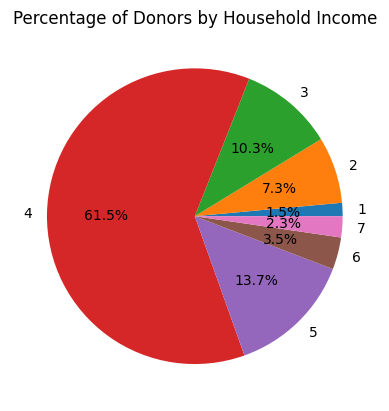

Text(0.5, 1.0, 'Donor/Nondonor Ratio by Household Income')

<Figure size 640x480 with 0 Axes>

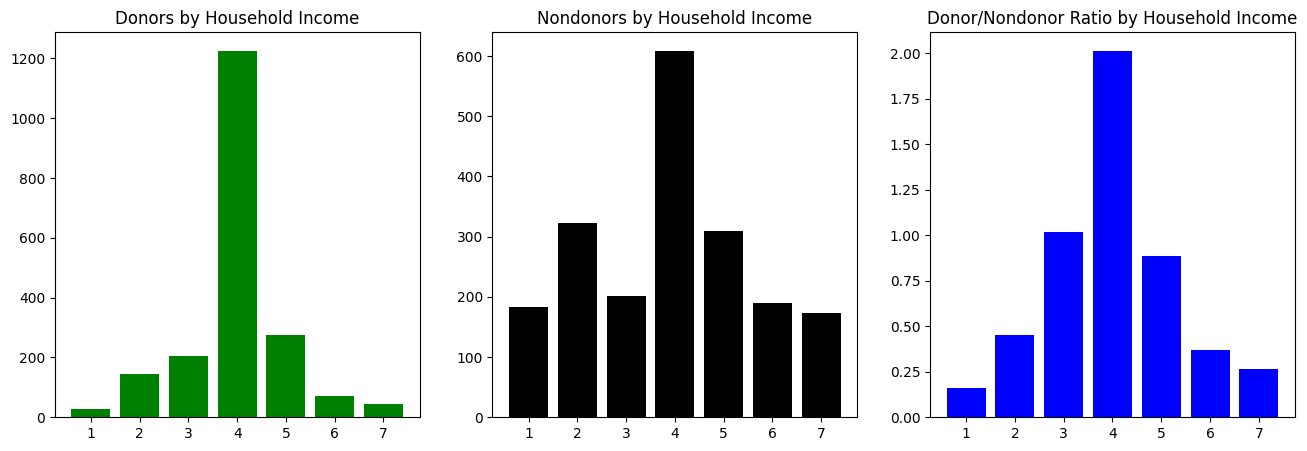

In [ ]:
# import needed libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import sklearn as sk

training = pd.read_csv('charitydataset_training.csv')
total_records = training.shape[0]

is_donor = training['donr'] == 1 #create mask to filter donors from nondonors
donors, nondonors = training[is_donor], training[~is_donor] #filter dataframe into donors and nondonors
donors_by_hinc = donors.groupby('hinc').size() #number of donors for each household income
nondonors_by_hinc = nondonors.groupby('hinc').size() #number of nondonors for each household income

donors_by_hinc_perc = donors_by_hinc / sum(donors_by_hinc) #for each hinc, determine percentage of donors
# make pie chart
plt.title('Percentage of Donors by Household Income')
donors_by_hinc_perc.plot.pie(y=donors_by_hinc_perc.index, autopct='%.1f%%')
plt.show()
# create bar charts to show distribution of donors and nondonors by household income
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5)) 
ax1.bar(donors_by_hinc.index, donors_by_hinc.values, color='green')
ax1.set_title('Donors by Household Income')
ax2.bar(nondonors_by_hinc.index, nondonors_by_hinc.values, color='black')
ax2.set_title('Nondonors by Household Income')
d_to_nd_hinc = donors_by_hinc / nondonors_by_hinc
ax3.bar(d_to_nd_hinc.index, d_to_nd_hinc.values, color='blue')
ax3.set_title('Donor/Nondonor Ratio by Household Income')

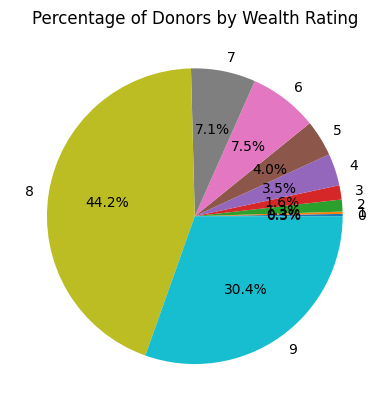

Text(0.5, 1.0, 'Donor/Nondonor Ratio by Wealth Rating')

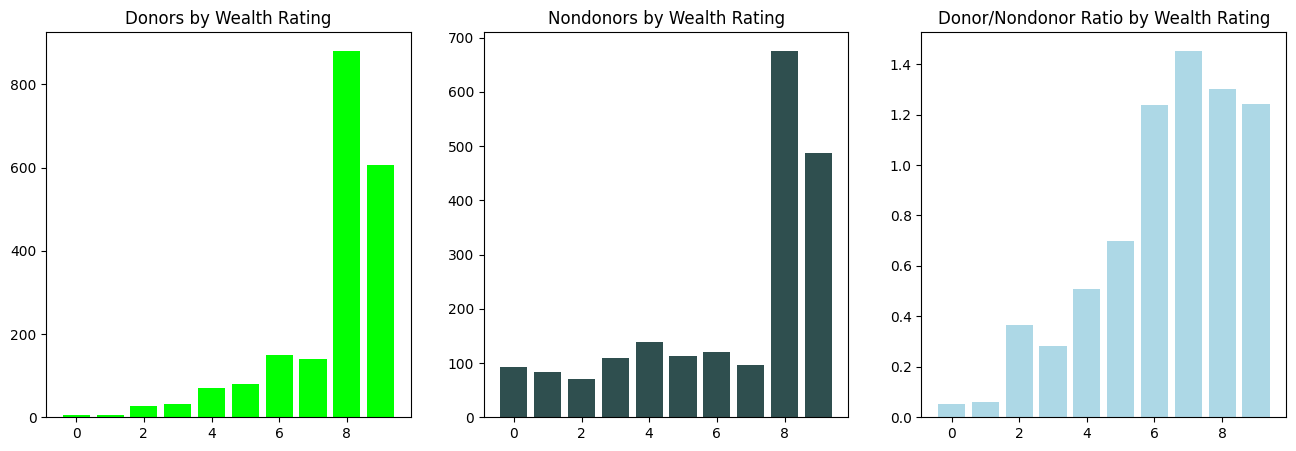

In [2]:
donors_by_wrat = donors.groupby('wrat').size() #number of donors for each wealth rating
nondonors_by_wrat = nondonors.groupby('wrat').size() #number of nondonors for each wealth rating

donors_by_wrat_perc = donors_by_wrat / sum(donors_by_wrat) #for each wrat, determine percentage of donors
# make pie chart
plt.title('Percentage of Donors by Wealth Rating')
donors_by_wrat_perc.plot.pie(y=donors_by_wrat_perc.index, autopct='%.1f%%')
plt.show()
# create bar charts to show distribution of donors and nondonors by wealth rating
fig2, (ax4, ax5, ax6) = plt.subplots(1, 3, figsize=(16, 5)) 
ax4.bar(donors_by_wrat.index, donors_by_wrat.values, color='lime')
ax4.set_title('Donors by Wealth Rating')
ax5.bar(nondonors_by_wrat.index, nondonors_by_wrat.values, color='darkslategray')
ax5.set_title('Nondonors by Wealth Rating')
d_to_nd_wrat = donors_by_wrat / nondonors_by_wrat
ax6.bar(d_to_nd_wrat.index, d_to_nd_wrat.values, color='lightblue')
ax6.set_title('Donor/Nondonor Ratio by Wealth Rating')

Text(0.5, 1.0, 'Percentage of Donors By Region')

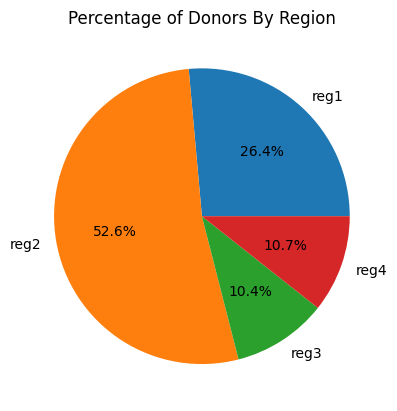

In [3]:
# determine percentage of donors by region
regions, donors_by_region = [],[]
for i in range(1,5):
    region = f'reg{i}' #region name
    regions.append(region) 
    donors_by_region.append(donors[donors[f'reg{i}'] == 1].shape[0]) # get number of donors per region
total_regions = sum(donors_by_region) # all donors
donors_by_region = np.array(donors_by_region) / total_regions #calculate percentage of donors per region
plt.pie(donors_by_region, labels=regions, autopct='%1.1f%%') #  make pie chart
plt.title('Percentage of Donors By Region')

Text(0.5, 1.0, 'Nondonors by Gender')

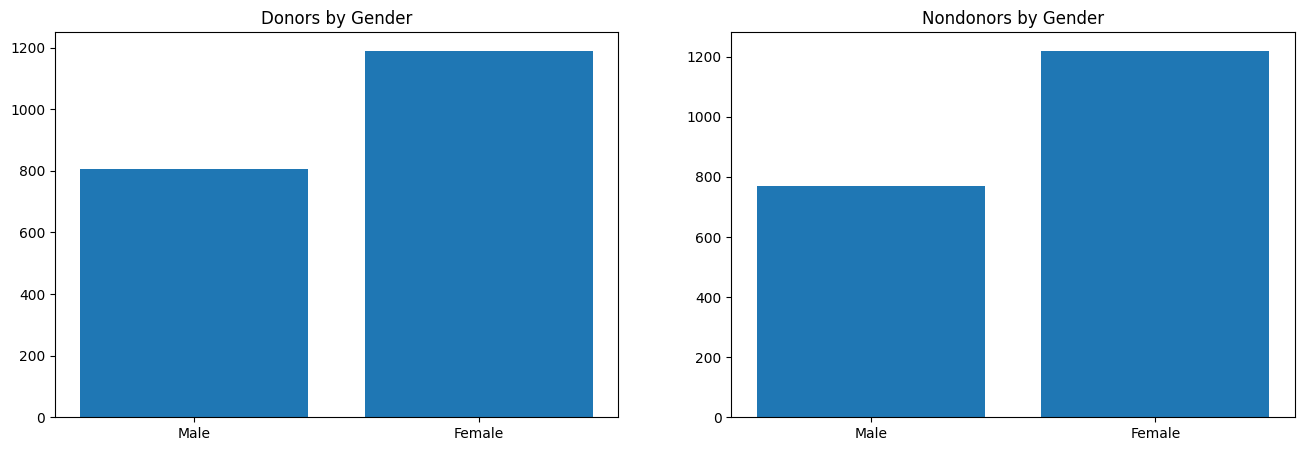

In [4]:
# make bar chart showing distribution of donors and nondonors by gender
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5)) 
is_male = donors['genf'] == 0
donors_male, donors_female = donors[is_male], donors[~is_male]
ax1.bar(['Male', 'Female'],[donors_male.shape[0], donors_female.shape[0]])
ax1.set_title('Donors by Gender')
is_male = nondonors['genf'] == 0
nondonors_male, nondonors_female = nondonors[is_male], nondonors[~is_male]
ax2.bar(['Male', 'Female'],[nondonors_male.shape[0], nondonors_female.shape[0]])
ax2.set_title('Nondonors by Gender')

<BarContainer object of 6 artists>

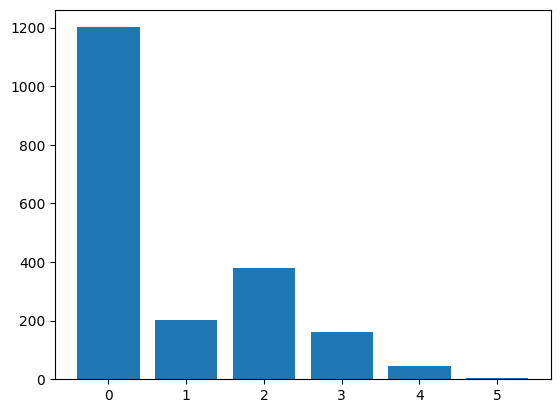

In [5]:
# make bar chart showing distribution of donors by number of children
donors_by_child = donors.groupby('chld').size()
plt.bar(donors_by_child.index, donors_by_child)

The code below was used to determine the best combination of fields to predict DONR.

In [ ]:
test = pd.read_csv('charitydataset_test.csv')
logreg = sk.linear_model.LogisticRegression(max_iter=1000)
# the following fields were found to give the highest accuracy score
donor_fields = ['reg1', 'reg2', 'reg3', 'reg4', 'wrat', 'home', 'chld', 'incm', 'npro', 'tgif']
X = training[donor_fields]
Y = training['donr']
donr_model = logreg.fit(X,Y) #train model
X = test[donor_fields]
Y = test['donr']
pred = donr_model.predict(X) #predict whether person is a donor
print('Accuracy score for model: ')
sk.metrics.accuracy_score(Y, pred) #determine accuracy of prediction

Accuracy score for model: 


0.8389494549058474

Below are several charts exploring data for DAMT.

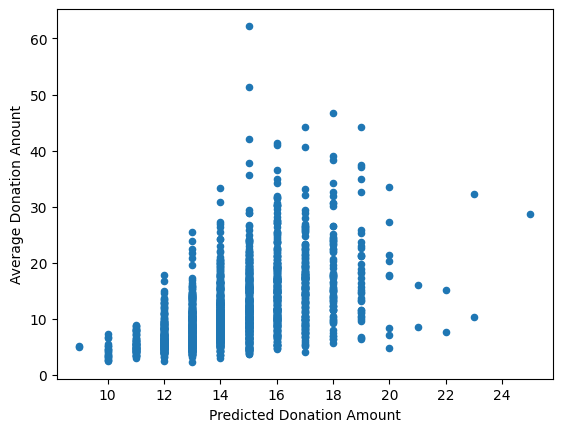

In [5]:
# scatter plot of donation amount and average gift
donors_by_average_gift = donors[['agif', 'damt']]
donors_by_average_gift.plot.scatter(x='damt', y='agif')
plt.xlabel("Predicted Donation Amount")
plt.ylabel("Average Donation Anount")
plt.show()

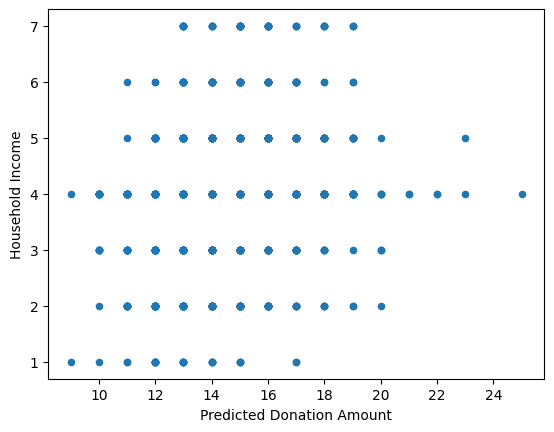

In [7]:
# scatter plot of donation amount and household income
donors_by_income = donors[['hinc', 'damt']]
donors_by_income.plot.scatter(x='damt', y='hinc')
plt.xlabel("Predicted Donation Amount")
plt.ylabel("Household Income")
plt.show()

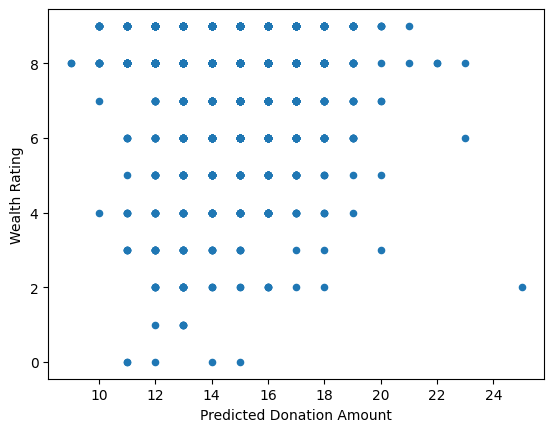

In [8]:
# scatter plot of donation amount and wealth rating
donors_by_income = donors[['wrat', 'damt']]
donors_by_income.plot.scatter(x='damt', y='wrat')
plt.xlabel("Predicted Donation Amount")
plt.ylabel("Wealth Rating")
plt.show()

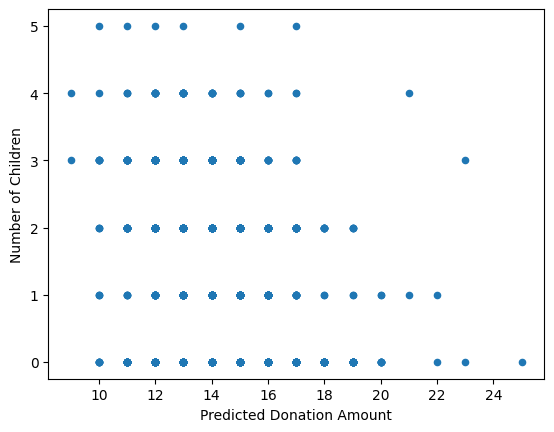

In [9]:
# scatter plot of donation amount and number of children
donors_by_income = donors[['chld', 'damt']]
donors_by_income.plot.scatter(x='damt', y='chld')
plt.xlabel("Predicted Donation Amount")
plt.ylabel("Number of Children")
plt.show()

The code below was used to determine the best combination of fields to predict DAMT.

In [11]:
# the following fields were found to give the lowest mean estimated error
donor_amount_fields = ['agif', 'chld', 'rgif', 'tgif', 'hinc', 'incm', 'plow', 'home', 'npro', 'tdon', 'tlag']
X = donors[donor_amount_fields] #get fields for donors to use for damt prediction
Y = donors['damt']
damt_model = sk.linear_model.LinearRegression()
damt_model.fit(X,Y) #train model
test_donors = test[test['donr'] == 1] #filter dataframe to only include donors
X = test_donors[donor_amount_fields] #get fields for donors in test data to use for damt prediction
Y = test_donors['damt']
pred = damt_model.predict(X) #predict donation amount
mae = sk.metrics.mean_absolute_error(Y, pred) #determine accuracy of predictions
print(f"Mean absolute error: {mae}")

Mean absolute error: 1.1344462868090581


The code below predicts DONR and DAMT for the scoring dataset.

In [ ]:
# Predict donr and damt for charitydataset_instructor_scoring.csv and save results
scoring_file_name = 'charitydataset_instructor_scoring.csv'
scoring = pd.read_csv(scoring_file_name)
X = scoring[donor_fields] #get fields to predict donors
scoring['donr'] = donr_model.predict(X) #create donr field, and populate with predictions from donr_model
scoring['damt'] = 0 #create damt field for scoring dataset, and initialize to zero
scoring_donors = scoring[scoring['donr'] == 1] #filter dataframe to obtain donors
X = scoring_donors[donor_amount_fields] #get fields for donors to use for damt prediction
scoring_dants = damt_model.predict(X) #predict damt
index = 0
for i, row in scoring.iterrows():
    #for each row in dataframe, if the person is a donor, update the damt field with the relevant predicted value
    if scoring.at[i, 'donr'] == 1:
        scoring.at[i, 'damt'] = round(scoring_dants[index]) #round to nearest even integer
        index += 1
scoring.to_csv(scoring_file_name, index=False) #save predictions